# 06 — Skill Matching

## Project overview
This notebook explicitly compares candidate skills with job-required skills. It parses lists, normalizes names, applies selected synonyms, extracts recognizable requirements, finds matched and missing skills, and calculates skill coverage.

**Output:** a detailed skill-matching dataset for the final ranking stage.

In [1]:
import pandas as pd
import numpy as np
import ast
import re
import matplotlib.pyplot as plt
from collections import Counter
from project_utils import (
    clean_skill_vocabulary, build_skill_index,
    find_skills_in_text, skill_match_score
)

print("Libraries imported successfully.")


Libraries imported successfully.


## 1. Load the processed dataset
Use `processed_data.csv` from Notebook 02.

In [2]:
DATA_PATH = r"D:\Instant AI\AI\Graduation Project\My Project\Data\processed_data.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (9544, 33)


,career_objective,skills,educational_institution_name,degree_names,passing_years,educational_results,result_types,major_field_of_studies,professional_company_names,start_dates,...,expiry_dates,job_position_name,educationaL_requirements,experiencere_requirement,skills_required,matched_score,candidate_text,job_text,candidate_text_length,job_text_length
0,big data analytics working and database wareho...,"['big data', 'hadoop', 'hive', 'python', 'mapr...",['the amity school of engineering & technology...,['b.tech'],['2019'],['n/a'],[none],['electronics'],['coca-cola'],['nov 2019'],...,NaN,senior software engineer,b.sc in computer science & engineering from a ...,at least 1 year,NaN,0.850000,big data analytics working and database wareho...,senior software engineer b.sc in computer scie...,653,257
1,fresher looking to join as a data analyst and ...,"['data analysis', 'data analytics', 'business ...","['delhi university - hansraj college', 'delhi ...","['b.sc (maths)', 'm.sc (science) (statistics)']","['2015', '2018']","['n/a', 'n/a']","['n/a', 'n/a']","['mathematics', 'statistics']",['bib consultancy'],['sep 2019'],...,NaN,machine learning (ml) engineer,m.sc in computer science & engineering or in a...,at least 5 year(s),NaN,0.750000,fresher looking to join as a data analyst and ...,machine learning (ml) engineer m.sc in compute...,554,534
2,NaN,"['software development', 'machine learning', '...","['birla institute of technology (bit), ranchi']",['b.tech'],['2018'],['n/a'],['n/a'],['electronics/telecommunication'],['axis bank limited'],['june 2018'],...,NaN,"executive/ senior executive- trade marketing, ...",master of business administration (mba),at least 3 years,brand promotion campaign management field supe...,0.416667,"['software development', 'machine learning', '...","executive/ senior executive- trade marketing, ...",446,365
3,to obtain a position in a fast-paced business ...,"['accounts payables', 'accounts receivables', ...","['martinez adult education, business training ...",['computer applications specialist certificate...,['2008'],[none],[none],['computer applications'],"['company name ï¼ city , state', 'company name...","['january 2011', 'january 2008', 'january 2006...",...,NaN,business development executive,bachelor/honors,1 to 3 years,fast typing skill ieltsinternet browsing & onl...,0.760000,to obtain a position in a fast-paced business ...,business development executive bachelor/honors...,1844,209
4,professional accountant with an outstanding wo...,"['analytical reasoning', 'compliance testing k...",['kent state university'],['bachelor of business administration'],[none],['3.84'],[none],['accounting'],"['company name', 'company name', 'company name...","['january 2016', 'january 2016', 'january 2012...",...,"['february 15, 2021']",senior ios engineer,bachelor of science (bsc) in computer science,at least 4 years,ios ios app developer ios application developm...,0.650000,professional accountant with an outstanding wo...,senior ios engineer bachelor of science (bsc) ...,1783,485


In [3]:
print(
    "Missing candidate skills:",
    df["skills"].isna().sum()
)

print(
    "Missing required skills:",
    df["skills_required"].isna().sum()
)


Missing candidate skills: 56
Missing required skills: 1701


In [4]:
print("Candidate skills example:")
print(df["skills"].iloc[0])

print("\nData type:")
print(type(df["skills"].iloc[0]))


Candidate skills example:
['big data', 'hadoop', 'hive', 'python', 'mapreduce', 'spark', 'java', 'machine learning', 'cloud', 'hdfs', 'yarn', 'core java', 'data science', 'c++', 'data structures', 'dbms', 'rdbms', 'informatica', 'talend', 'amazon redshift', 'microsoft azure']

Data type:
<class 'str'>


## 2. Parse skill lists
The original skill fields are text representations of Python lists. `ast.literal_eval` converts valid list representations into Python lists.

In [5]:
def parse_skill_list(value):
    if pd.isna(value):
        return []

    try:
        parsed = ast.literal_eval(value)

        if isinstance(parsed, list):
            return parsed

        return []

    except (ValueError, SyntaxError):
        return []


In [6]:
test_skills = df["skills"].iloc[0]

print("Before:")
print(test_skills)

print("\nAfter:")
print(parse_skill_list(test_skills))


Before:
['big data', 'hadoop', 'hive', 'python', 'mapreduce', 'spark', 'java', 'machine learning', 'cloud', 'hdfs', 'yarn', 'core java', 'data science', 'c++', 'data structures', 'dbms', 'rdbms', 'informatica', 'talend', 'amazon redshift', 'microsoft azure']

After:
['big data', 'hadoop', 'hive', 'python', 'mapreduce', 'spark', 'java', 'machine learning', 'cloud', 'hdfs', 'yarn', 'core java', 'data science', 'c++', 'data structures', 'dbms', 'rdbms', 'informatica', 'talend', 'amazon redshift', 'microsoft azure']


In [7]:
df["candidate_skills"] = df["skills"].apply(
    parse_skill_list
)

df[["skills", "candidate_skills"]].head()


,skills,candidate_skills
0,"['big data', 'hadoop', 'hive', 'python', 'mapr...","[big data, hadoop, hive, python, mapreduce, sp..."
1,"['data analysis', 'data analytics', 'business ...","[data analysis, data analytics, business analy..."
2,"['software development', 'machine learning', '...","[software development, machine learning, deep ..."
3,"['accounts payables', 'accounts receivables', ...","[accounts payables, accounts receivables, acco..."
4,"['analytical reasoning', 'compliance testing k...","[analytical reasoning, compliance testing know..."


In [8]:
df["required_skills"] = df["skills_required"].apply(
    parse_skill_list
)

df[["skills_required", "required_skills"]].head()


,skills_required,required_skills
0,NaN,[]
1,NaN,[]
2,brand promotion campaign management field supe...,[]
3,fast typing skill ieltsinternet browsing & onl...,[]
4,ios ios app developer ios application developm...,[]


## 3. Normalize skill names
Lowercase skill names and remove unnecessary characters and whitespace to reduce simple formatting differences.

In [9]:
def normalize_skill(skill):
    skill = str(skill).lower()

    skill = re.sub(
        r"[^a-zA-Z0-9+#.\s]",
        " ",
        skill
    )

    skill = re.sub(
        r"\s+",
        " ",
        skill
    ).strip()

    return skill


In [10]:
test_skills = [
    "Python",
    "PYTHON",
    "Machine Learning",
    "SQL",
    "C++"
]

print([
    normalize_skill(skill)
    for skill in test_skills
])


['python', 'python', 'machine learning', 'sql', 'c++']


In [11]:
df["candidate_skills_normalized"] = (
    df["candidate_skills"].apply(
        lambda skills: [
            normalize_skill(skill)
            for skill in skills
            if str(skill).strip()
        ]
    )
)


In [12]:
df["required_skills_normalized"] = (
    df["required_skills"].apply(
        lambda skills: [
            normalize_skill(skill)
            for skill in skills
            if str(skill).strip()
        ]
    )
)


## 4. Remove duplicates and apply synonyms
Duplicate names are removed while selected equivalents such as `ml` and `machine learning` are standardized.

In [13]:
def unique_skills(skills):
    return list(dict.fromkeys(skills))


df["candidate_skills_normalized"] = (
    df["candidate_skills_normalized"]
    .apply(unique_skills)
)

df["required_skills_normalized"] = (
    df["required_skills_normalized"]
    .apply(unique_skills)
)


In [14]:
skill_synonyms = {
    "ml": "machine learning",
    "machine-learning": "machine learning",
    "ai": "artificial intelligence",
    "artificial-intelligence": "artificial intelligence",
    "nlp": "natural language processing",
    "natural-language-processing": "natural language processing",
    "py": "python",
    "power bi": "powerbi",
    "power-bi": "powerbi",
    "js": "javascript",
    "react js": "react",
    "reactjs": "react",
    "node js": "node.js",
    "nodejs": "node.js",
    "auto cad": "autocad",
    "c sharp": "c#",
    "dot net": ".net"
}


In [15]:
def apply_skill_synonyms(skills):
    normalized = []

    for skill in skills:
        skill = skill_synonyms.get(
            skill,
            skill
        )

        normalized.append(skill)

    return list(dict.fromkeys(normalized))


df["candidate_skills_final"] = (
    df["candidate_skills_normalized"]
    .apply(apply_skill_synonyms)
)


## 5. Build the skill vocabulary and extract required skills
Candidate skills provide the vocabulary used to recognize skills inside job requirements.

In [16]:
skill_counter = Counter(
    skill
    for skills in df["candidate_skills_final"]
    for skill in set(skills)
)

all_candidate_skills = clean_skill_vocabulary(skill_counter, min_freq=3, max_words=4)
skill_index = build_skill_index(all_candidate_skills)

print("Vocabulary size:", len(all_candidate_skills))
print(all_candidate_skills[:30])

Vocabulary size: 2559
['.net', '.ney vb asp', '10key by touch', '2 tier', '2000', '2k', '3d', '3d modeling', '3d printing', '3ds max', '3dsmax', '5 why', '5s', '5s expert', '8d', 'a p', 'a r', 'a+', 'aaa security model', 'aardwolf', 'ability to prioritize', 'academic', 'access', 'access control', 'access database', 'account management', 'account management and development', 'account reconciliation', 'account reconciliation expert', 'account reconciliation processes']


In [17]:
df["candidate_text"] = df["candidate_text"].fillna("")
df["job_text"] = df["job_text"].fillna("")

df["candidate_skills_extracted"] = df["candidate_text"].apply(
    lambda t: find_skills_in_text(t, skill_index, skill_synonyms)
)
df["required_skills_extracted"] = df["job_text"].apply(
    lambda t: find_skills_in_text(t, skill_index, skill_synonyms)
)

In [18]:
df["required_skills_final"] = df["required_skills_extracted"]
df["required_skill_count"] = df["required_skills_final"].apply(len)

print("Rows with required skills:", (df["required_skill_count"] > 0).sum())
print("Rows without required skills:", (df["required_skill_count"] == 0).sum())

Rows with required skills: 9544
Rows without required skills: 0


In [19]:
df[
    [
        "job_text",
        "required_skills_extracted"
    ]
].head(20)

,job_text,required_skills_extracted
0,senior software engineer b.sc in computer scie...,"[documentation, software engineer, technical s..."
1,machine learning (ml) engineer m.sc in compute...,"[application development, data analysis, funct..."
2,"executive/ senior executive- trade marketing, ...","[business administration, excel, marketing, mb..."
3,business development executive bachelor/honors...,"[business development, fast, quality, reliable..."
4,senior ios engineer bachelor of science (bsc) ...,"[api, application development, integration, io..."
5,ai engineer bachelors or masters degree in com...,"[analytical skills, artificial intelligence, d..."
6,senior ios engineer bachelor of science (bsc) ...,"[api, application development, integration, io..."
7,senior ios engineer bachelor of science (bsc) ...,"[api, application development, integration, io..."
8,mechanical engineer bachelor of science (bsc) ...,"[machinery, maintenance, mechanical, mechanica..."
9,business development executive bachelor/honors...,"[business development, fast, quality, reliable..."


In [20]:
df["required_skills_final"] = (
    df["required_skills_extracted"]
    .apply(unique_skills)
)

df["required_skill_count"] = (
    df["required_skills_final"].apply(len)
)

print(
    "Rows with required skills:",
    (df["required_skill_count"] > 0).sum()
)

print(
    "Rows without required skills:",
    (df["required_skill_count"] == 0).sum()
)


Rows with required skills: 9544
Rows without required skills: 0


## 6. Match candidate and required skills
Set intersection identifies matched skills; the remaining required skills are reported as missing skills.

In [21]:
results = df.apply(
    lambda row: skill_match_score(
        row["candidate_skills_extracted"],
        row["required_skills_final"]
    ),
    axis=1
)

df["skill_coverage"] = [r[0] for r in results]
df["matched_skills"] = [r[1] for r in results]
df["missing_skills"] = [r[2] for r in results]
df["matched_skill_count"] = df["matched_skills"].apply(len)

In [22]:
df["matched_skill_count"] = (
    df["matched_skills"].apply(len)
)

df["required_skill_count"] = (
    df["required_skills_final"].apply(len)
)

print(
    df[
        [
            "required_skill_count",
            "matched_skill_count"
        ]
    ].head()
)


   required_skill_count  matched_skill_count
0                     4                    0
1                    11                    5
2                     8                    0
3                     5                    1
4                     9                    0


In [23]:
import joblib

skill_vocabulary = sorted(
    set(all_candidate_skills).union(
        *df["required_skills_final"].tolist()
    )
)

SKILL_RESOURCES_PATH = (
    r"D:\Instant AI\AI\Graduation Project\My Project\Models\skill_resources.pkl"
)

joblib.dump(
    {
        "skill_vocabulary": skill_vocabulary,
        "skill_synonyms": skill_synonyms
    },
    SKILL_RESOURCES_PATH
)

print("Skill resources saved.")
print("Vocabulary size:", len(skill_vocabulary))

Skill resources saved.
Vocabulary size: 2559


## 7. Calculate skill coverage
Coverage equals matched required skills divided by recognized required skills. Rows with no recognized requirements remain undefined rather than being treated as zero.

In [24]:
df["skill_coverage_percentage"] = df["skill_coverage"] * 100

In [25]:
df[
    [
        "job_position_name",
        "candidate_skills_final",
        "required_skills_final",
        "matched_skills",
        "missing_skills",
        "skill_coverage_percentage"
    ]
].head(20)


,job_position_name,candidate_skills_final,required_skills_final,matched_skills,missing_skills,skill_coverage_percentage
0,senior software engineer,"[big data, hadoop, hive, python, mapreduce, sp...","[documentation, software engineer, technical s...",[],"[documentation, software engineer, technical s...",0.000000
1,machine learning (ml) engineer,"[data analysis, data analytics, business analy...","[application development, data analysis, funct...","[data analysis, machine learning, machine lear...","[application development, functional, leadersh...",37.878788
2,"executive/ senior executive- trade marketing, ...","[software development, machine learning, deep ...","[business administration, excel, marketing, mb...",[],"[business administration, excel, marketing, mb...",0.000000
3,business development executive,"[accounts payables, accounts receivables, acco...","[business development, fast, quality, reliable...",[fast],"[business development, quality, reliable, typing]",20.000000
4,senior ios engineer,"[analytical reasoning, compliance testing know...","[api, application development, integration, io...",[],"[api, application development, integration, io...",0.000000
5,ai engineer,"[microsoft applications, network security, net...","[analytical skills, artificial intelligence, d...",[analytical skills (partial)],"[artificial intelligence, data analysis, docum...",3.571429
6,senior ios engineer,"[machine learning, linear regression, ridge re...","[api, application development, integration, io...",[requirement analysis (partial)],"[api, application development, integration, io...",5.555556
7,senior ios engineer,"[maintenance, corrective maintenance, document...","[api, application development, integration, io...",[ui design (partial)],"[api, application development, integration, io...",5.555556
8,mechanical engineer,"[python, machine learning, mysql, data mining,...","[machinery, maintenance, mechanical, mechanica...",[],"[machinery, maintenance, mechanical, mechanica...",0.000000
9,business development executive,"[django, python, relational databases, restapi...","[business development, fast, quality, reliable...",[business development (partial)],"[fast, quality, reliable, typing]",10.000000


In [26]:
df[
    df["required_skill_count"] > 0
][
    [
        "job_position_name",
        "candidate_skills_final",
        "required_skills_final",
        "matched_skills",
        "missing_skills",
        "skill_coverage_percentage"
    ]
].head(10)


,job_position_name,candidate_skills_final,required_skills_final,matched_skills,missing_skills,skill_coverage_percentage
0,senior software engineer,"[big data, hadoop, hive, python, mapreduce, sp...","[documentation, software engineer, technical s...",[],"[documentation, software engineer, technical s...",0.000000
1,machine learning (ml) engineer,"[data analysis, data analytics, business analy...","[application development, data analysis, funct...","[data analysis, machine learning, machine lear...","[application development, functional, leadersh...",37.878788
2,"executive/ senior executive- trade marketing, ...","[software development, machine learning, deep ...","[business administration, excel, marketing, mb...",[],"[business administration, excel, marketing, mb...",0.000000
3,business development executive,"[accounts payables, accounts receivables, acco...","[business development, fast, quality, reliable...",[fast],"[business development, quality, reliable, typing]",20.000000
4,senior ios engineer,"[analytical reasoning, compliance testing know...","[api, application development, integration, io...",[],"[api, application development, integration, io...",0.000000
5,ai engineer,"[microsoft applications, network security, net...","[analytical skills, artificial intelligence, d...",[analytical skills (partial)],"[artificial intelligence, data analysis, docum...",3.571429
6,senior ios engineer,"[machine learning, linear regression, ridge re...","[api, application development, integration, io...",[requirement analysis (partial)],"[api, application development, integration, io...",5.555556
7,senior ios engineer,"[maintenance, corrective maintenance, document...","[api, application development, integration, io...",[ui design (partial)],"[api, application development, integration, io...",5.555556
8,mechanical engineer,"[python, machine learning, mysql, data mining,...","[machinery, maintenance, mechanical, mechanica...",[],"[machinery, maintenance, mechanical, mechanica...",0.000000
9,business development executive,"[django, python, relational databases, restapi...","[business development, fast, quality, reliable...",[business development (partial)],"[fast, quality, reliable, typing]",10.000000


In [27]:
def has_nested(skills):
    return any(
        a != b and f" {a} " in f" {b} "
        for a in skills for b in skills
    )

print("Rows with nested required skills:", df["required_skills_final"].apply(has_nested).sum())   # must be 0

Rows with nested required skills: 3409


## 8. Validate the skill-matching results
Check total rows, rows with requirements, rows with matches, coverage limits, and examples.

In [28]:
print("Total rows:", len(df))

print(
    "Rows with required skills:",
    (df["required_skill_count"] > 0).sum()
)

print(
    "Rows without required skills:",
    (df["required_skill_count"] == 0).sum()
)

print(
    "Rows with at least one match:",
    (df["matched_skill_count"] > 0).sum()
)

print(
    "Average skill coverage:",
    df["skill_coverage_percentage"].mean()
)

print(
    "Maximum skill coverage:",
    df["skill_coverage_percentage"].max()
)


Total rows: 9544
Rows with required skills: 9544
Rows without required skills: 0
Rows with at least one match: 5624
Average skill coverage: 9.955883765345206
Maximum skill coverage: 100.0


In [29]:
df[
    df["matched_skill_count"] > 0
][
    [
        "job_position_name",
        "required_skills_final",
        "matched_skills",
        "missing_skills",
        "skill_coverage_percentage"
    ]
].head(20)


,job_position_name,required_skills_final,matched_skills,missing_skills,skill_coverage_percentage
1,machine learning (ml) engineer,"[application development, data analysis, funct...","[data analysis, machine learning, machine lear...","[application development, functional, leadersh...",37.878788
3,business development executive,"[business development, fast, quality, reliable...",[fast],"[business development, quality, reliable, typing]",20.000000
5,ai engineer,"[analytical skills, artificial intelligence, d...",[analytical skills (partial)],"[artificial intelligence, data analysis, docum...",3.571429
6,senior ios engineer,"[api, application development, integration, io...",[requirement analysis (partial)],"[api, application development, integration, io...",5.555556
7,senior ios engineer,"[api, application development, integration, io...",[ui design (partial)],"[api, application development, integration, io...",5.555556
9,business development executive,"[business development, fast, quality, reliable...",[business development (partial)],"[fast, quality, reliable, typing]",10.000000
12,machine learning (ml) engineer,"[application development, data analysis, funct...","[data analysis (partial), statistical analysis...","[application development, functional, leadersh...",9.090909
13,mechanical designer,"[autocad, cad, documentation, drawings, manufa...",[mechanical engineering (partial)],"[autocad, cad, documentation, drawings, manufa...",5.555556
15,database administrator (dba),"[asp.net, backup, bi, clustering, data integri...","[data integrity (partial), mongodb, mysql, sol...","[asp.net, backup, bi, clustering, database, da...",17.500000
16,system administrator (operation & maintenance ...,"[account management, backup, cisco, classifica...","[database, documentation, hardware, network in...","[account management, backup, cisco, classifica...",29.166667


In [30]:
df[
    df["skill_coverage_percentage"].notna()
].sort_values(
    "skill_coverage_percentage",
    ascending=False
)[
    [
        "job_position_name",
        "required_skills_final",
        "matched_skills",
        "missing_skills",
        "skill_coverage_percentage"
    ]
].head(20)


,job_position_name,required_skills_final,matched_skills,missing_skills,skill_coverage_percentage
8680,executive/ sr. executive -it,"[hardware, mail, networking, security, softwar...","[hardware, mail, networking, security, softwar...",[],100.000000
8809,mechanical engineer,"[machinery, maintenance, mechanical, mechanica...","[machinery, maintenance, mechanical, mechanica...",[],90.000000
5694,mechanical engineer,"[machinery, maintenance, mechanical, mechanica...","[machinery, maintenance, mechanical, mechanica...",[],90.000000
5857,mechanical engineer,"[machinery, maintenance, mechanical, mechanica...","[machinery, maintenance, mechanical, mechanica...",[],90.000000
1559,mechanical engineer,"[machinery, maintenance, mechanical, mechanica...","[machinery, maintenance, mechanical, mechanica...",[],90.000000
9106,senior software engineer,"[documentation, software engineer, technical s...","[documentation, software engineer (partial), t...",[],87.500000
3116,senior software engineer,"[documentation, software engineer, technical s...","[documentation, software engineer (partial), t...",[],87.500000
5112,executive/ sr. executive -it,"[hardware, mail, networking, security, softwar...","[hardware, networking, security, software inst...",[mail],83.333333
2447,executive/ sr. executive -it,"[hardware, mail, networking, security, softwar...","[hardware, networking, security, software inst...",[mail],83.333333
6676,mechanical engineer,"[machinery, maintenance, mechanical, mechanica...","[machinery, maintenance, mechanical, mechanica...",[troubleshooting],80.000000


In [31]:
valid_coverage = df[
    df["skill_coverage_percentage"].notna()
]["skill_coverage_percentage"]

print("Minimum coverage:", valid_coverage.min())
print("Maximum coverage:", valid_coverage.max())

print(
    "Values below 0:",
    (valid_coverage < 0).sum()
)

print(
    "Values above 100:",
    (valid_coverage > 100).sum()
)


Minimum coverage: 0.0
Maximum coverage: 100.0
Values below 0: 0
Values above 100: 0


## 9. Visualize and prepare final skill features
Review the coverage distribution and verify the final skill-related columns.

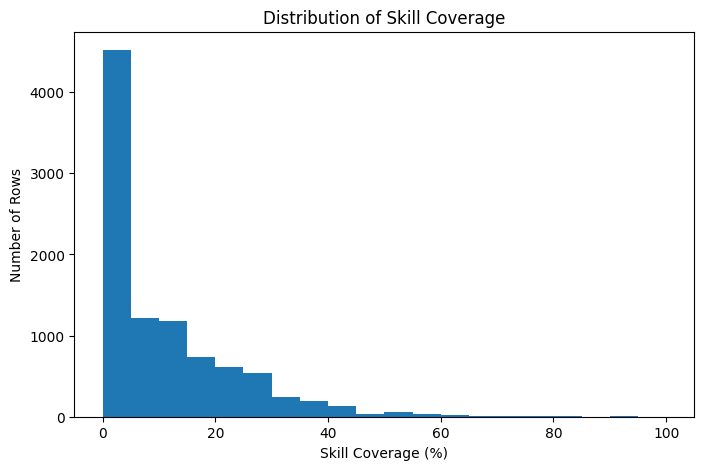

In [32]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["skill_coverage_percentage"].dropna(),
    bins=20
)

plt.xlabel("Skill Coverage (%)")
plt.ylabel("Number of Rows")
plt.title("Distribution of Skill Coverage")

plt.show()


In [33]:
final_columns = [
    "candidate_skills",
    "candidate_skills_normalized",
    "candidate_skills_final",
    "required_skills_extracted",
    "required_skills_final",
    "matched_skills",
    "missing_skills",
    "matched_skill_count",
    "required_skill_count",
    "skill_coverage",
    "skill_coverage_percentage"
]

print("Final skill-matching columns:")

for column in final_columns:
    print(
        column,
        "->",
        column in df.columns
    )


Final skill-matching columns:
candidate_skills -> True
candidate_skills_normalized -> True
candidate_skills_final -> True
required_skills_extracted -> True
required_skills_final -> True
matched_skills -> True
missing_skills -> True
matched_skill_count -> True
required_skill_count -> True
skill_coverage -> True
skill_coverage_percentage -> True


## 10. Save the skill-matching dataset
Save candidate skills, required skills, matched skills, missing skills, counts, and coverage measures.

In [34]:
OUTPUT_PATH = r"D:\Instant AI\AI\Graduation Project\My Project\Data\skills_matching_results.csv"

df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("Saved successfully:")
print(OUTPUT_PATH)

print("\nFinal dataset shape:")
print(df.shape)


Saved successfully:
D:\Instant AI\AI\Graduation Project\My Project\Data\skills_matching_results.csv

Final dataset shape:
(9544, 47)


## Final validation
Confirm the final row count and skill-matching statistics.

**Next stage:** Notebook 07 combines TF-IDF similarity, Word2Vec similarity, and skill coverage into the final ranking pipeline.

In [35]:
print("========== FINAL CHECK ==========")

print("Total rows:", len(df))

print(
    "Rows with required skills:",
    (df["required_skill_count"] > 0).sum()
)

print(
    "Rows with at least one match:",
    (df["matched_skill_count"] > 0).sum()
)

print(
    "Average skill coverage:",
    df["skill_coverage_percentage"].mean()
)

print(
    "Maximum skill coverage:",
    df["skill_coverage_percentage"].max()
)

print("=================================")


========== FINAL CHECK ==========
Total rows: 9544
Rows with required skills: 9544
Rows with at least one match: 5624
Average skill coverage: 9.955883765345206
Maximum skill coverage: 100.0
